In [ ]:
import os
import random
import re
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


TASK A

In [ ]:
import requests

# Load Tiny Shakespeare directly from the raw text file
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

response = requests.get(url)
response.raise_for_status()

train_text = response.text

print("Dataset loaded successfully")
print("\nNumber of characters in training text:", len(train_text))

print("\nFirst 1000 characters:\n")
print(train_text[:1000])

Dataset loaded successfully

Number of characters in training text: 1115394

First 1000 characters:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, 

In [ ]:
# Explore basic properties of the text
lines = [line.strip() for line in train_text.splitlines() if line.strip()]

print("Number of non-empty lines:", len(lines))
print("\nFirst 10 non-empty lines:")
for i, line in enumerate(lines[:10], start=1):
    print(f"{i}: {line}")

Number of non-empty lines: 32777

First 10 non-empty lines:
1: First Citizen:
2: Before we proceed any further, hear me speak.
3: All:
4: Speak, speak.
5: First Citizen:
6: You are all resolved rather to die than to famish?
7: All:
8: Resolved. resolved.
9: First Citizen:
10: First, you know Caius Marcius is chief enemy to the people.


In [ ]:
# Convert to lowercase and perform light normalization.
# We retain apostrophes inside words, while replacing other punctuation with spaces.
text = train_text.lower()
text = re.sub(r"[^a-z'\s]", " ", text)
text = re.sub(r"\s+", " ", text).strip()

print("Cleaned text sample:\n")
print(text[:1000])

Cleaned text sample:

first citizen before we proceed any further hear me speak all speak speak first citizen you are all resolved rather to die than to famish all resolved resolved first citizen first you know caius marcius is chief enemy to the people all we know't we know't first citizen let us kill him and we'll have corn at our own price is't a verdict all no more talking on't let it be done away away second citizen one word good citizens first citizen we are accounted poor citizens the patricians good what authority surfeits on would relieve us if they would yield us but the superfluity while it were wholesome we might guess they relieved us humanely but they think we are too dear the leanness that afflicts us the object of our misery is as an inventory to particularise their abundance our sufferance is a gain to them let us revenge this with our pikes ere we become rakes for the gods know i speak this in hunger for bread not in thirst for revenge second citizen would you proceed

In [ ]:
# Tokenize the complete text into words.
# filters='' is used because punctuation was already handled during cleaning.
tokenizer = Tokenizer(filters="", lower=False, oov_token="<OOV>")
tokenizer.fit_on_texts([text])

word_to_index = tokenizer.word_index
index_to_word = {index: word for word, index in word_to_index.items()}

# +1 because index 0 is reserved for padding.
vocab_size = len(word_to_index) + 1

token_ids = tokenizer.texts_to_sequences([text])[0]

print("Vocabulary size (including padding index 0):", vocab_size)
print("Total word tokens:", len(token_ids))
print("\nFirst 20 vocabulary entries:")
for word, idx in list(word_to_index.items())[:20]:
    print(f"{word:15s} -> {idx}")

Vocabulary size (including padding index 0): 12633
Total word tokens: 204062

First 20 vocabulary entries:
<OOV>           -> 1
the             -> 2
and             -> 3
to              -> 4
i               -> 5
of              -> 6
you             -> 7
my              -> 8
a               -> 9
that            -> 10
in              -> 11
is              -> 12
not             -> 13
for             -> 14
with            -> 15
me              -> 16
it              -> 17
be              -> 18
your            -> 19
his             -> 20


In [ ]:
# Generate variable-length sequences for next-word prediction.
# At most 10 previous words are used to predict the next word.
MAX_CONTEXT = 10
sequences = []

for i in range(1, len(token_ids)):
    start = max(0, i - MAX_CONTEXT)
    sequence = token_ids[start:i + 1]   # context words + target word
    sequences.append(sequence)

# All sequences are padded to MAX_CONTEXT + 1:
# first MAX_CONTEXT positions = input, final position = target.
max_sequence_len = MAX_CONTEXT + 1

padded_sequences = pad_sequences(
    sequences,
    maxlen=max_sequence_len,
    padding="pre",
    truncating="pre"
)

print("Number of sequences:", len(padded_sequences))
print("Padded sequence shape:", padded_sequences.shape)
print("\nExample padded sequences:")
print(padded_sequences[:5])

Number of sequences: 204061
Padded sequence shape: (204061, 11)

Example padded sequences:
[[  0   0   0   0   0   0   0   0   0  89 270]
 [  0   0   0   0   0   0   0   0  89 270 140]
 [  0   0   0   0   0   0   0  89 270 140  36]
 [  0   0   0   0   0   0  89 270 140  36 969]
 [  0   0   0   0   0  89 270 140  36 969 144]]


In [ ]:
# Separate predictors (X) and next-word labels (y)
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

# Shuffle before splitting
indices = np.arange(len(X))
np.random.shuffle(indices)

X = X[indices]
y = y[indices]

# 80% training, 20% validation
split_index = int(0.8 * len(X))

X_train = X[:split_index]
y_train = y[:split_index]
X_val = X[split_index:]
y_val = y[split_index:]

print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Input sequence length:", X_train.shape[1])
print("Jayaraksha 24BAD044")

X shape: (204061, 10)
y shape: (204061,)

Training samples: 163248
Validation samples: 40813
Input sequence length: 10
Jayaraksha 24BAD044


TASK B

In [8]:
EMBEDDING_DIM = 100
RNN_UNITS = 128

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        input_length=MAX_CONTEXT,
        mask_zero=True
    ),
    SimpleRNN(RNN_UNITS),
    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Build explicitly so the full summary is displayed consistently.
model.build(input_shape=(None, MAX_CONTEXT))
model.summary()
print("JAYARAKSHA 24BAD044")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 100)        │     1,263,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        29,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 12633)          │     1,629,657 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,922,269 (11.15 MB)

 Trainable params: 2,922,269 (11.15 MB)

 Non-trainable params: 0 (0.00 B)

JAYARAKSHA 24BAD044


TASK C

In [9]:
EPOCHS = 15
BATCH_SIZE = 128

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 115s 88ms/step - accuracy: 0.0426 - loss: 6.7863 - val_accuracy: 0.0666 - val_loss: 6.4778
Epoch 2/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 98s 77ms/step - accuracy: 0.0784 - loss: 6.1255 - val_accuracy: 0.0812 - val_loss: 6.3199
Epoch 3/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 90s 71ms/step - accuracy: 0.0936 - loss: 5.7690 - val_accuracy: 0.0865 - val_loss: 6.3153
Epoch 4/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 162s 87ms/step - accuracy: 0.1058 - loss: 5.4790 - val_accuracy: 0.0875 - val_loss: 6.3647
Epoch 5/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 138s 83ms/step - accuracy: 0.1182 - loss: 5.2174 - val_accuracy: 0.0857 - val_loss: 6.4403
Epoch 6/15
1276/1276 ━━━━━━━━━━━━━━━━━━━━ 90s 71ms/step - accuracy: 0.1334 - loss: 4.9736 - val_accuracy: 0.0838 - val_loss: 6.5310


In [10]:
# Record final metrics
final_train_accuracy = history.history["accuracy"][-1]
final_val_accuracy = history.history["val_accuracy"][-1]
final_train_loss = history.history["loss"][-1]
final_val_loss = history.history["val_loss"][-1]

print(f"Training Accuracy   : {final_train_accuracy:.4f}")
print(f"Validation Accuracy : {final_val_accuracy:.4f}")
print(f"Training Loss       : {final_train_loss:.4f}")
print(f"Validation Loss     : {final_val_loss:.4f}")

Training Accuracy   : 0.1334
Validation Accuracy : 0.0838
Training Loss       : 4.9736
Validation Loss     : 6.5310


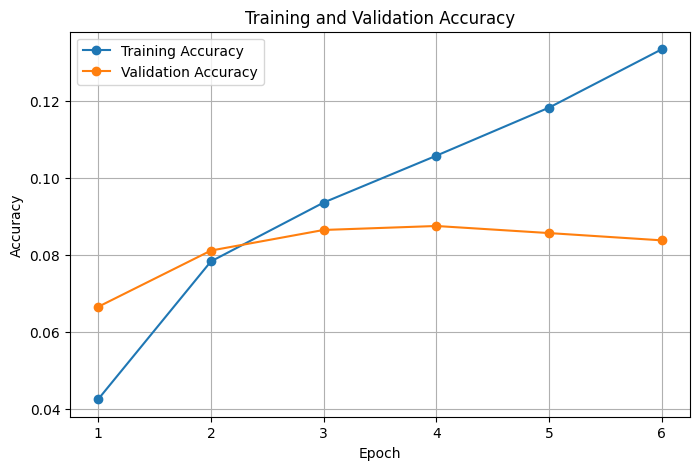

JAYARAKSHA 24BAD044


In [11]:
# Accuracy vs Epoch
epochs_ran = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()
print("JAYARAKSHA 24BAD044")

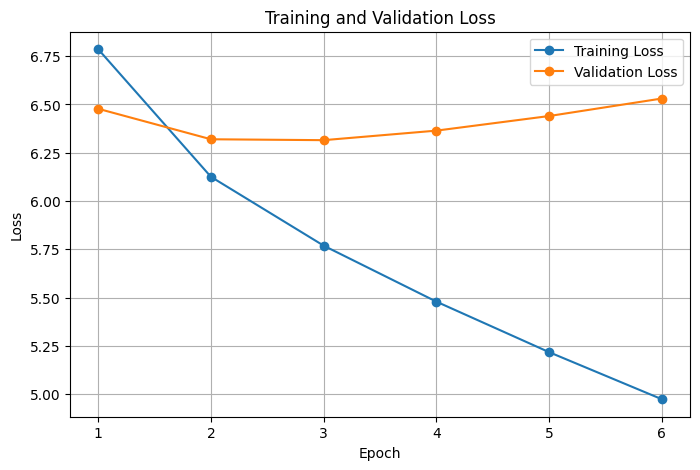

JAYARAKSHA 24BAD044


In [13]:
# Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(epochs_ran, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs_ran, history.history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()
print("JAYARAKSHA 24BAD044")

TASK D

In [12]:
def sample_next_word(probabilities, temperature=0.8):
    probabilities = np.asarray(probabilities).astype("float64")

    # Avoid numerical problems with log(0)
    probabilities = np.log(probabilities + 1e-10) / temperature
    probabilities = np.exp(probabilities)
    probabilities = probabilities / np.sum(probabilities)

    return np.random.choice(len(probabilities), p=probabilities)


def generate_text(seed_text, next_words=30, temperature=0.8):
    generated_text = seed_text.lower().strip()

    for _ in range(next_words):
        # Apply the same cleaning used during training.
        cleaned_seed = re.sub(r"[^a-z'\s]", " ", generated_text)
        cleaned_seed = re.sub(r"\s+", " ", cleaned_seed).strip()

        token_list = tokenizer.texts_to_sequences([cleaned_seed])[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=MAX_CONTEXT,
            padding="pre",
            truncating="pre"
        )

        predicted_probabilities = model.predict(token_list, verbose=0)[0]

        # Padding index 0 should never be generated.
        predicted_probabilities[0] = 0

        predicted_index = sample_next_word(
            predicted_probabilities,
            temperature=temperature
        )

        predicted_word = index_to_word.get(predicted_index)

        if predicted_word is None or predicted_word == "<OOV>":
            continue

        generated_text += " " + predicted_word

    return generated_text

In [14]:
# Generate multiple samples with different seeds
seeds = [
    "to be or not to be",
    "romeo",
    "my lord",
    "the king"
]

for seed in seeds:
    print("=" * 90)
    print("Seed:", seed)
    print("Generated text:")
    print(generate_text(seed, next_words=40, temperature=0.8))
    print()

Seed: to be or not to be
Generated text:
to be or not to be revenged yet him to seek my lady's chance and hath coming well with you will had not we coriolanus be my lord i will be more but that i must not corioli i fly to the duke of york duke

Seed: romeo
Generated text:
romeo tell them your blindfold rose i am sure i am a doubt of the country of me it not warwick well else how he did his mind northumberland sir you duke of york and good same sake i'll be clown

Seed: my lord
Generated text:
my lord the ministers that i must go my counsel is not children we am a dream o' the prince richard come to love thee ready it cannot hear you surely to be baptista i am thee all to he in the

Seed: the king
Generated text:
the king on't with that the nobility falsely as it shall be gone by your foe this tear his saint against the gentle worst cannot didst for the blinding summer names or in the mourning blood to lose thy horse for all



In [15]:
# Optional experiment: compare temperatures
seed = "to be or not to be"

for temperature in [0.5, 0.8, 1.2]:
    print("=" * 90)
    print(f"Temperature = {temperature}")
    print(generate_text(seed, next_words=40, temperature=temperature))
    print()

Temperature = 0.5
to be or not to be a little of my house and i have heard him to the crown of your own king edward iv i am a man that you have not to my house and if you are it shall not so you shall

Temperature = 0.8
to be or not to be revenged with my fay gloucester and you have give me it is a great duke vincentio romeo and you to be you yet my heart so then with a traitor northumberland o he is not at your company and by

Temperature = 1.2
to be or not to be deed with waked that sadly my very ought know fears they indeed this are causes 'twas true to oath now fire myself thou hast no montague so more said nought no less ladies all same king richard ii familiar welcome



In [16]:
# Save the trained model
model.save("tiny_shakespeare_rnn.keras")
print("Model saved as tiny_shakespeare_rnn.keras")
print("JAYARAKSHA 24BAD044")

Model saved as tiny_shakespeare_rnn.keras
JAYARAKSHA 24BAD044
